In [1]:
# Importing necessary libraries
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import xgboost
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from pycaret.classification import setup

In [2]:
# Reading training CSV file
path = "O:/"
Eelgrass_NOVANA_prediction_model = pd.read_csv(path +'training.csv')

In [3]:
# Extracting the response variable and predictors
response_var = Eelgrass_NOVANA_prediction_model['Eelgrass_class_10']
predictors = Eelgrass_NOVANA_prediction_model.drop(columns=['Eelgrass_Coverage_pct', 'Eelgrass_class_10', 'Eelgrass_class_30',
                                                         'Eelgrass_class_50', 'Light_attenuation_df', 'sbs_5th_df', 'slope_sea_df',
                                                         'optical_depth_newbathy_df', 'TAU_df', 'refRast_df', 'MEI_d_2024_df', 'Sediment_df'])

In [4]:
# Combining into a single data frame
data = pd.concat([response_var, predictors], axis=1)

In [5]:
# Removing rows with missing values
data = data.dropna()

In [6]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Selecting the three final parameters
final_params = ['sbt_95th_df', 'Light_at_depth_pct_new_df', 'MEI_df']
X = data[final_params].dropna()

# Calculating VIF for each predictor
vif_data = pd.DataFrame()
vif_data['Predictor'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

print("="*60)
print("VARIANCE INFLATION FACTOR (VIF) ANALYSIS")
print("="*60)
print(vif_data.to_string(index=False))
print("="*60)

VARIANCE INFLATION FACTOR (VIF) ANALYSIS
                Predictor      VIF
              sbt_95th_df 4.829054
Light_at_depth_pct_new_df 3.126134
                   MEI_df 2.616405


In [7]:
# Splitting data into training and testing sets
train_data, test_data = train_test_split(data, test_size=0.2, random_state=42)

In [8]:
# Separating features and target
X_train = train_data.drop(columns=['Eelgrass_class_10', 'Bathymetry_new_df'])
y_train = train_data['Eelgrass_class_10']

In [9]:
X_test = test_data.drop(columns=['Eelgrass_class_10', 'Bathymetry_new_df'])
y_test = test_data['Eelgrass_class_10']

In [10]:
# Creating a DataFrame for PyCaret
train_pycaret = X_train.copy()
train_pycaret['Eelgrass_class_10'] = y_train

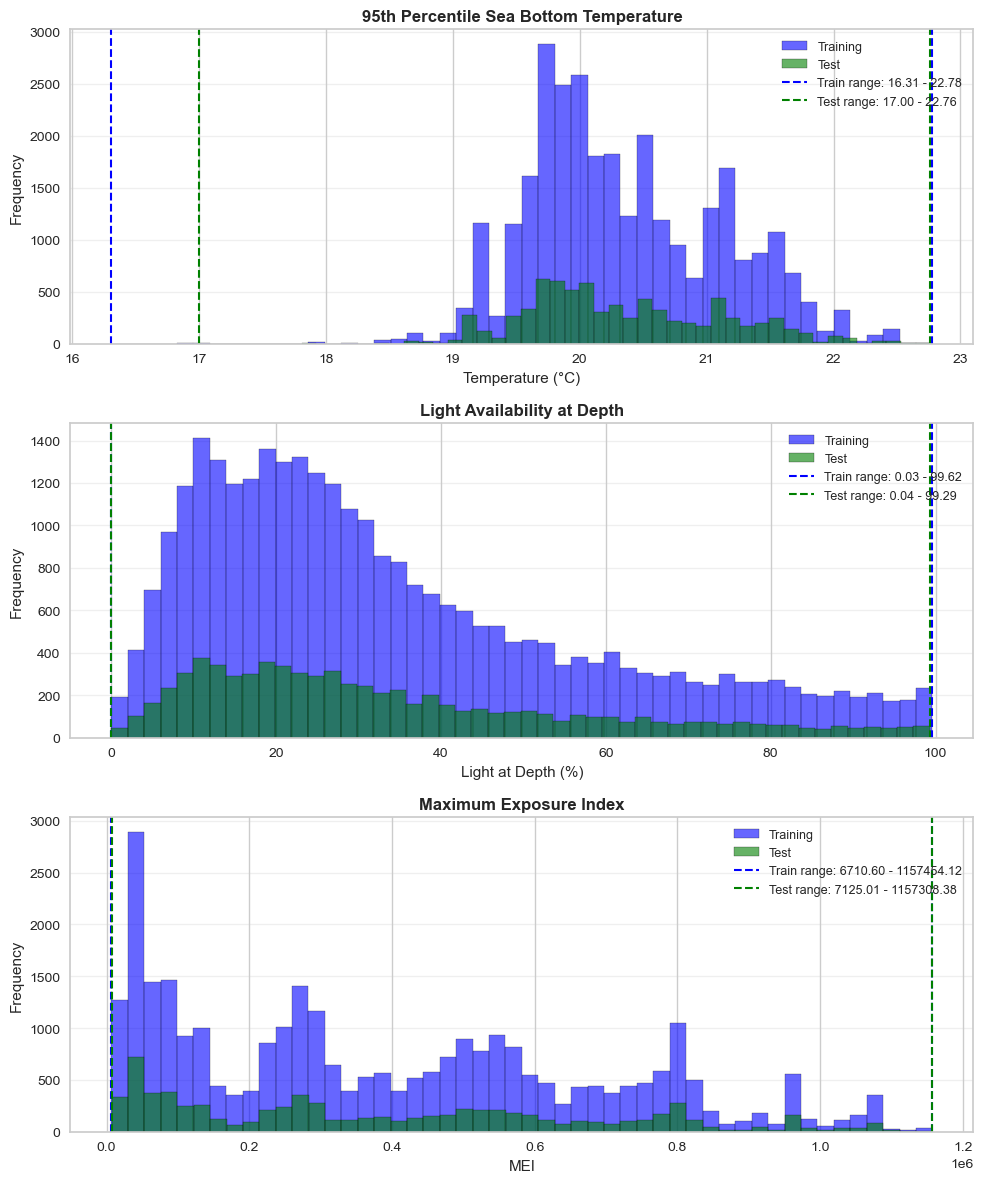

In [94]:
##To plot the ranges for traing and test data: added in supplementary
import matplotlib.pyplot as plt
import numpy as np

# Creating figure with 3 subplots (one for each feature)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

features = [
    ('sbt_95th_df', 'Temperature (°C)', '95th Percentile Sea Bottom Temperature'),
    ('Light_at_depth_pct_new_df', 'Light at Depth (%)', 'Light Availability at Depth'),
    ('MEI_df', 'MEI', 'Maximum Exposure Index')
]

for idx, (feature, xlabel, title) in enumerate(features):
    ax = axes[idx]
    
    # Plotting histograms
    ax.hist(X_train[feature], bins=50, alpha=0.6, label='Training', color='blue', edgecolor='black')
    ax.hist(X_test[feature], bins=50, alpha=0.6, label='Test', color='green', edgecolor='black')
    
    # Adding vertical lines for min/max ranges
    train_min, train_max = X_train[feature].min(), X_train[feature].max()
    test_min, test_max = X_test[feature].min(), X_test[feature].max()
    
    ax.axvline(train_min, color='blue', linestyle='--', linewidth=1.5, label=f'Train range: {train_min:.2f} - {train_max:.2f}')
    ax.axvline(train_max, color='blue', linestyle='--', linewidth=1.5)
    ax.axvline(test_min, color='green', linestyle='--', linewidth=1.5, label=f'Test range: {test_min:.2f} - {test_max:.2f}')
    ax.axvline(test_max, color='green', linestyle='--', linewidth=1.5)
    
    # Labels and formatting
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Frequency', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('train_test_distribution_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [98]:
# Initialize PyCaret setup
# This will automatically handle data preprocessing, feature engineering, and algorithm selection
start_time = time.time()
clf_setup = setup(
    data=train_pycaret,
    target='Eelgrass_class_10',
    session_id=3000,
    normalize=True,
    transformation=False,
    ignore_features=['Bathymetry_new_df'] if 'Bathymetry_new_df' in train_pycaret.columns else None,
    log_experiment=False,
    experiment_name='eelgrass_classification',
    fold= 10
)

,Description,Value
0,Session id,3000
1,Target,Eelgrass_class_10
2,Target type,Binary
3,Original data shape,"(29997, 4)"
4,Transformed data shape,"(29997, 4)"
5,Transformed train set shape,"(20997, 4)"
6,Transformed test set shape,"(9000, 4)"
7,Numeric features,3
8,Preprocess,True
9,Imputation type,simple


In [99]:
from pycaret.classification import create_model, evaluate_model
# Import PyCaret regression module
from pycaret.classification import *

In [100]:
# Compare all models to find the best performers
best_models = compare_models(sort='Accuracy', n_select=3)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
rf,Random Forest Classifier,0.8004,0.8713,0.6999,0.7572,0.7273,0.5703,0.5715,0.3880
et,Extra Trees Classifier,0.7940,0.8653,0.7023,0.7424,0.7217,0.5584,0.5590,0.1950
xgboost,Extreme Gradient Boosting,0.7775,0.8496,0.6619,0.7287,0.6936,0.5196,0.5212,0.2260
dt,Decision Tree Classifier,0.7613,0.7475,0.6900,0.6847,0.6873,0.4942,0.4943,0.0280
lightgbm,Light Gradient Boosting Machine,0.7594,0.8325,0.6146,0.7137,0.6601,0.4756,0.4791,0.4100
knn,K Neighbors Classifier,0.7486,0.8128,0.6581,0.6734,0.6656,0.4642,0.4644,0.3880
gbc,Gradient Boosting Classifier,0.7043,0.7653,0.4932,0.6463,0.5592,0.3428,0.3500,0.4760
ada,Ada Boost Classifier,0.6664,0.7103,0.4848,0.5732,0.5249,0.2707,0.2732,0.1340
qda,Quadratic Discriminant Analysis,0.6413,0.6628,0.0945,0.7184,0.1670,0.0860,0.1595,0.0140
nb,Naive Bayes,0.6263,0.6558,0.0637,0.5776,0.1146,0.0427,0.0851,0.0130


In [ ]:
##Identifying rf as the best model from Pycaret- next step is gridsearch to find the best parameter

In [ ]:
# ============================================================================
#HYPERPARAMETER TUNING WITH GRIDSEARCH
# ============================================================================
print("\n" + "="*80)
print("HYPERPARAMETER TUNING - GRIDSEARCH CV")
print("="*80)

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report, confusion_matrix
import numpy as np
import time
import json

# Define parameter grid
param_grid = {
    'n_estimators': [200, 300, 400, 500, 600, 700],
    'max_depth': [10, 20, 30, 40, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 3, 4, 5],
    'max_features': ['sqrt', 'log2'],
    'bootstrap': [True],
    'class_weight': ['balanced', None]
}

# Calculating total combinations
total_combinations = np.prod([len(v) for v in param_grid.values()])
print(f"\nParameter Grid:")
for param, values in param_grid.items():
    print(f"  {param}: {values}")
print(f"\nTotal combinations to test: {total_combinations}")
print(f"With 5-fold CV: {total_combinations * 5} model fits")
print(f"Estimated time: ~{total_combinations * 5 * 2 / 60:.0f} minutes (rough estimate)")

# Initializing Random Forest
rf = RandomForestClassifier(random_state=42, n_jobs=-1, oob_score=True, verbose=0)

# GridSearchCV with stratified 5-fold CV
print("\nInitializing GridSearchCV...")
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,  # 5-fold cross-validation on TRAINING data
    scoring='roc_auc',  # Use AUC as primary metric
    n_jobs=-1,
    verbose=2,
    return_train_score=True,
    refit=True  # Refit best model on full training set
)

print("\n" + "="*80)
print("STARTING GRID SEARCH...")
print("="*80)

start_time = time.time()
grid_search.fit(X_train, y_train)
elapsed_time = time.time() - start_time

print(f"\n✓ Grid Search completed in {elapsed_time/60:.2f} minutes ({elapsed_time:.0f} seconds)")

In [ ]:
# ============================================================================
# BEST PARAMETERS & CV RESULTS
# ============================================================================
print("\n" + "="*80)
print("BEST PARAMETERS FROM GRIDSEARCH")
print("="*80)

print("\nBest Parameters:")
for param, value in grid_search.best_params_.items():
    print(f"  {param}: {value}")

print(f"\nBest CV AUC Score (5-fold on training): {grid_search.best_score_:.4f}")

# Getting the best model
best_rf = grid_search.best_estimator_
print(f"OOB Score (best model): {best_rf.oob_score_:.4f}")

In [ ]:
##By identifying the best model from pycaret and running gridsearch- chosen final model with the parameter combination as below:

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import cross_validate
import numpy as np
import pandas as pd

In [12]:
##The choice of parameters is a result of multiple gridsearch, testing the prediction, osv before fnalizing these parameters:
rf_final = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42
)

In [13]:
print("Training the model...")
rf_final.fit(X_train, y_train)

Training the model...


RandomForestClassifier(class_weight='balanced', max_depth=20,
                       min_samples_leaf=5, min_samples_split=10,
                       n_estimators=300, random_state=42)

In [14]:
# 3. PREDICTING on test data
print("Predicting on test data...")
y_pred = rf_final.predict(X_test)

Predicting on test data...


In [15]:
# 4. Evaluating performance on independent test data
print("\nModel Performance on Test Data:")
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print("\nConfusion Matrix:")
print(cm)


Model Performance on Test Data:
Accuracy:  0.8031
Precision: 0.7198
Recall:    0.7826
F1 Score:  0.7499

Confusion Matrix:
[[3809  862]
 [ 615 2214]]


In [108]:
# Evaluating
y_true = y_test.values
print("="*70)
print("MODEL PERFORMANCE")
print("="*70)
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1:        {f1_score(y_true, y_pred):.4f}")

cm = confusion_matrix(y_true, y_pred)
print(f"\nConfusion Matrix:")
print(f"TN={cm[0,0]}, FP={cm[0,1]}")
print(f"FN={cm[1,0]}, TP={cm[1,1]}")

# Calculating areas
GRID_SIZE = 50  # meters
CELL_AREA = GRID_SIZE * GRID_SIZE  # 2,500 m^2

# Counting predictions
n_predicted_eelgrass = np.sum(y_pred == 1)
n_predicted_no_eelgrass = np.sum(y_pred == 0)
n_actual_eelgrass = np.sum(y_true == 1)
n_actual_no_eelgrass = np.sum(y_true == 0)

# Calculating areas in m^2
predicted_eelgrass_area_m2 = n_predicted_eelgrass * CELL_AREA
predicted_no_eelgrass_area_m2 = n_predicted_no_eelgrass * CELL_AREA
actual_eelgrass_area_m2 = n_actual_eelgrass * CELL_AREA
actual_no_eelgrass_area_m2 = n_actual_no_eelgrass * CELL_AREA

# Converting to hectares (1 hectare = 10,000 m^2)
predicted_eelgrass_area_ha = predicted_eelgrass_area_m2 / 10_000
actual_eelgrass_area_ha = actual_eelgrass_area_m2 / 10_000

print("\n" + "="*70)
print("AREA ANALYSIS (TEST SET)")
print("="*70)
print(f"Grid cell size: {GRID_SIZE}m x {GRID_SIZE}m = {CELL_AREA:,} m^2")
print(f"Total test samples: {len(y_test):,}")
print(f"\nPREDICTED:")
print(f"  Eelgrass cells: {n_predicted_eelgrass:,} -> {predicted_eelgrass_area_m2:,.0f} m^2 ({predicted_eelgrass_area_ha:.2f} ha)")
print(f"  No eelgrass cells: {n_predicted_no_eelgrass:,} -> {predicted_no_eelgrass_area_m2:,.0f} m^2")
print(f"\nACTUAL:")
print(f"  Eelgrass cells: {n_actual_eelgrass:,} -> {actual_eelgrass_area_m2:,.0f} m^2 ({actual_eelgrass_area_ha:.2f} ha)")
print(f"  No eelgrass cells: {n_actual_no_eelgrass:,} -> {actual_no_eelgrass_area_m2:,.0f} m^2")
print(f"\nDIFFERENCE:")
area_diff_m2 = predicted_eelgrass_area_m2 - actual_eelgrass_area_m2
area_diff_ha = predicted_eelgrass_area_ha - actual_eelgrass_area_ha
print(f"  Eelgrass area difference: {area_diff_m2:+,.0f} m^2 ({area_diff_ha:+.2f} ha)")
print(f"  Relative difference: {(area_diff_m2/actual_eelgrass_area_m2)*100:+.1f}%")
print("="*70)

MODEL PERFORMANCE
Accuracy:  0.8031
Precision: 0.7198
Recall:    0.7826
F1:        0.7499

Confusion Matrix:
TN=3809, FP=862
FN=615, TP=2214

AREA ANALYSIS (TEST SET)
Grid cell size: 50m x 50m = 2,500 m^2
Total test samples: 7,500

PREDICTED:
  Eelgrass cells: 3,076 -> 7,690,000 m^2 (769.00 ha)
  No eelgrass cells: 4,424 -> 11,060,000 m^2

ACTUAL:
  Eelgrass cells: 2,829 -> 7,072,500 m^2 (707.25 ha)
  No eelgrass cells: 4,671 -> 11,677,500 m^2

DIFFERENCE:
  Eelgrass area difference: +617,500 m^2 (+61.75 ha)
  Relative difference: +8.7%


In [ ]:
# ============================================================
# CALCULATING TRAINING SET METRICS
# ============================================================
print("\n" + "="*80)
print("CALCULATING TRAINING SET METRICS")
print("="*80)

# Model is already fitted above - just using it directly
y_train_pred_final = rf_final.predict(X_train)
y_train_proba_final = rf_final.predict_proba(X_train)[:, 1]

# Calculating training metrics
train_metrics = {
    'Accuracy': accuracy_score(y_train, y_train_pred_final),
    'Precision': precision_score(y_train, y_train_pred_final),
    'Recall': recall_score(y_train, y_train_pred_final),
    'F1': f1_score(y_train, y_train_pred_final),
    'AUC': roc_auc_score(y_train, y_train_proba_final)
}

print("Training Set Performance:")
print(f"  Accuracy:  {train_metrics['Accuracy']:.4f}")
print(f"  Precision: {train_metrics['Precision']:.4f}")
print(f"  Recall:    {train_metrics['Recall']:.4f}")
print(f"  F1-Score:  {train_metrics['F1']:.4f}")
print(f"  AUC-ROC:   {train_metrics['AUC']:.4f}")

# ============================================================
#  OUT-OF-BAG (OOB) VALIDATION
# ============================================================
print("\n" + "="*80)
print("OUT-OF-BAG (OOB) VALIDATION")
print("="*80)

# refitting same RF model but with OOB enabled
# 
rf_oob = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    oob_score=True,  # This requires a new model
    random_state=42
)

# Fitting the OOB model (this is necessary for OOB score)
rf_oob.fit(X_train, y_train)

# Getting OOB score
train_score_oob = rf_oob.score(X_train, y_train)
oob_score = rf_oob.oob_score_
oob_gap = train_score_oob - oob_score

print(f"\nTraining Accuracy: {train_score_oob:.4f}")
print(f"OOB Accuracy:      {oob_score:.4f}")
print(f"OOB Gap:           {oob_gap:+.4f}")

# ============================================================
# ORGANIZING METRICS INTO DICTIONARIES
# ============================================================

# Test metrics
test_metrics = {
    'Accuracy': accuracy_test,
    'Precision': precision_test,
    'Recall': recall_test,
    'F1': f1_test,
    'AUC': roc_auc_test
}

# CV metrics (already calculated above)
cv_metrics = {
    'Accuracy': accuracy_cv,
    'Precision': precision_cv,
    'Recall': recall_cv,
    'F1': f1_cv,
    'AUC': roc_auc_cv
}

# ============================================================
# CALCULATING GENERALIZATION GAPS
# ============================================================

# Train-Test Gap
train_test_gaps = []
for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']:
    gap = train_metrics[metric] - test_metrics[metric]
    train_test_gaps.append(gap)
avg_train_test_gap = np.mean(train_test_gaps)

# CV-Test Gap
cv_test_gaps = []
for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']:
    gap = cv_metrics[metric] - test_metrics[metric]
    cv_test_gaps.append(gap)
avg_cv_test_gap = np.mean(cv_test_gaps)

# ============================================================

# ============================================================
# CREATING COMPARISON TABLE
# ============================================================
import pandas as pd

summary_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC'],
    'Training': [
        train_metrics['Accuracy'],
        train_metrics['Precision'],
        train_metrics['Recall'],
        train_metrics['F1'],
        train_metrics['AUC']
    ],
    'CV (10-fold)': [
        cv_metrics['Accuracy'],
        cv_metrics['Precision'],
        cv_metrics['Recall'],
        cv_metrics['F1'],
        cv_metrics['AUC']
    ],
    'Test': [
        test_metrics['Accuracy'],
        test_metrics['Precision'],
        test_metrics['Recall'],
        test_metrics['F1'],
        test_metrics['AUC']
    ],
    'Train-Test Gap': [
        train_metrics['Accuracy'] - test_metrics['Accuracy'],
        train_metrics['Precision'] - test_metrics['Precision'],
        train_metrics['Recall'] - test_metrics['Recall'],
        train_metrics['F1'] - test_metrics['F1'],
        train_metrics['AUC'] - test_metrics['AUC']
    ]
})

print("="*80)
print("COMPARISON TABLE (FOR PUBLICATION)")
print("="*80)
print(summary_table.round(4).to_string(index=False))
print("\n")

# Save to CSV
summary_table.round(4).to_csv('generalization_summary.csv', index=False)
print("Table saved: generalization_summary.csv\n")


In [ ]:
##Estimation uncertainty/confidence metices

In [ ]:
# ============================================================
# COMPREHENSIVE CONFIDENCE AND UNCERTAINTY METRICS
# ============================================================

def calculate_all_confidence_metrics(model, X, predictions=None):
    
    # Get probabilities from model
    proba = model.predict_proba(X)
    prob_absence = proba[:, 0]   # P(class=0) - for ALL locations
    prob_presence = proba[:, 1]  # P(class=1) - for ALL locations
    
    # Get predictions
    if predictions is None:
        predictions = model.predict(X)
    
    # ========================================================================
    # OCCURRENCE PROBABILITIES (Habitat Suitability - for ALL locations)
    # ========================================================================
    # These are the RAW probabilities - useful for habitat suitability maps
    occurrence_prob_presence = prob_presence
    occurrence_prob_absence = prob_absence
    
    # ========================================================================
    # PREDICTION CONFIDENCE (How certain is the model in its prediction?)
    # ========================================================================
    # Combined: confidence in whatever was predicted
    vote_confidence = np.where(predictions == 1, prob_presence, prob_absence)
    n_trees_voting = (vote_confidence * model.n_estimators).astype(int)
    
    # Conditional: confidence ONLY where we predicted that class
    confidence_if_present = np.where(predictions == 1, prob_presence, np.nan)
    confidence_if_absent = np.where(predictions == 0, prob_absence, np.nan)
    
    # ========================================================================
    # UNCERTAINTY METRICS (Distance from decision boundary)
    # ========================================================================
    # Uncertainty is highest at probability = 0.5, lowest at 0 or 1
    uncertainty = 1 - 2 * np.abs(prob_presence - 0.5)
    confidence_score = 1 - uncertainty  # Overall confidence (inverse of uncertainty)
    
    # ========================================================================
    # CREATING RESULTS DATAFRAME
    # ========================================================================
    results = pd.DataFrame({
        'prediction_label': predictions,
        
        # OCCURRENCE PROBABILITIES (for habitat suitability mapping)
        'prob_presence': occurrence_prob_presence,
        'prob_absence': occurrence_prob_absence,
        
        # PREDICTION CONFIDENCE (combined - for all locations)
        'vote_confidence': vote_confidence,
        'n_trees_voting': n_trees_voting,
        
        # PREDICTION CONFIDENCE (conditional - only where predicted)
        'confidence_if_present': confidence_if_present,
        'confidence_if_absent': confidence_if_absent,
        
        # UNCERTAINTY METRICS
        'uncertainty': uncertainty,
        'confidence_score': confidence_score,
    })
    
    # ========================================================================
    # ADDING CATEGORICAL LEVELS
    # ========================================================================
    
    # Occurrence probability levels (for habitat suitability classification)
    results['prob_presence_level'] = pd.cut(
        occurrence_prob_presence,
        bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
        labels=['Very Low', 'Low', 'Moderate', 'High', 'Very High'],
        include_lowest=True
    )
    
    results['prob_absence_level'] = pd.cut(
        occurrence_prob_absence,
        bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
        labels=['Very Low', 'Low', 'Moderate', 'High', 'Very High'],
        include_lowest=True
    )
    
    # Vote confidence levels (combined prediction confidence)
    results['vote_conf_level'] = pd.cut(
        vote_confidence,
        bins=[0, 0.6, 0.7, 0.8, 0.9, 1.0],
        labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'],
        include_lowest=True
    )
    
    # Conditional confidence levels (only where predicted present)
    results['conf_present_level'] = pd.cut(
        confidence_if_present,
        bins=[0, 0.6, 0.7, 0.8, 0.9, 1.0],
        labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'],
        include_lowest=True
    )
    
    # Conditional confidence levels (only where predicted absent)
    results['conf_absent_level'] = pd.cut(
        confidence_if_absent,
        bins=[0, 0.6, 0.7, 0.8, 0.9, 1.0],
        labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'],
        include_lowest=True
    )
    
    # Uncertainty levels
    results['uncertainty_level'] = pd.cut(
        uncertainty,
        bins=[0, 0.3, 0.5, 0.7, 1.0],
        labels=['Low', 'Medium', 'High', 'Very High'],
        include_lowest=True
    )
    
    return results



# Calculate all metrics
confidence_results = calculate_all_confidence_metrics(rf_final, X_test)

# Display summary
print("="*70)
print("CONFIDENCE METRICS SUMMARY")
print("="*70)

print("\n1. OCCURRENCE PROBABILITY (Habitat Suitability)")
print("-"*70)
print(confidence_results['prob_presence_level'].value_counts().sort_index())

print("\n2. PREDICTION CONFIDENCE (Combined)")
print("-"*70)
print(confidence_results['vote_conf_level'].value_counts().sort_index())

print("\n3. UNCERTAINTY DISTRIBUTION")
print("-"*70)
print(confidence_results['uncertainty_level'].value_counts().sort_index())

print("\n4. PREDICTIONS BREAKDOWN")
print("-"*70)
print(f"Total predictions: {len(confidence_results)}")
print(f"Predicted Present: {(confidence_results['prediction_label']==1).sum()} "
      f"({(confidence_results['prediction_label']==1).sum()/len(confidence_results)*100:.1f}%)")
print(f"Predicted Absent:  {(confidence_results['prediction_label']==0).sum()} "
      f"({(confidence_results['prediction_label']==0).sum()/len(confidence_results)*100:.1f}%)")

print("\n5. HIGH CONFIDENCE PREDICTIONS")
print("-"*70)
high_conf = confidence_results[confidence_results['vote_confidence'] > 0.8]
print(f"High confidence (>0.8): {len(high_conf)} ({len(high_conf)/len(confidence_results)*100:.1f}%)")

print("\n6. UNCERTAIN PREDICTIONS (Near Decision Boundary)")
print("-"*70)
uncertain = confidence_results[confidence_results['uncertainty'] > 0.5]
print(f"Uncertain (>0.5): {len(uncertain)} ({len(uncertain)/len(confidence_results)*100:.1f}%)")

print("="*70)

In [ ]:
# ============================================================
# CALCULATING FOR TEST SET
# ============================================================
print("="*70)
print("COMBINED CONFIDENCE & UNCERTAINTY ANALYSIS - TEST SET")
print("="*70)

# Calculating all metrics
test_metrics = calculate_all_confidence_metrics(
    rf_final,
    X_test,
    predictions=y_pred
)

# Adding actual values
test_metrics['Actual'] = y_test.values

print(f"\nTotal test samples: {len(test_metrics)}")
print(f"Number of trees: {rf_final.n_estimators}")

# Summary statistics
print("\n" + "="*70)
print("VOTE-BASED CONFIDENCE")
print("="*70)
print(test_metrics['vote_confidence'].describe())
print("\nDistribution:")
print(test_metrics['vote_conf_level'].value_counts().sort_index())

print("\n" + "="*70)
print("UNCERTAINTY (BOUNDARY-BASED)")
print("="*70)
print(test_metrics['uncertainty'].describe())
print("\nDistribution:")
print(test_metrics['uncertainty_level'].value_counts().sort_index())

# ============================================================
# 2. RELATIONSHIP BETWEEN METRICS
# ============================================================
print("\n" + "="*70)
print("RELATIONSHIP: VOTE CONFIDENCE vs UNCERTAINTY")
print("="*70)

# Calculating correlation
correlation = np.corrcoef(test_metrics['vote_confidence'], 
                         test_metrics['uncertainty'])[0, 1]
print(f"Correlation: {correlation:.4f}")

# Cross-tabulation
print("\nCross-tabulation:")
crosstab = pd.crosstab(
    test_metrics['vote_conf_level'],
    test_metrics['uncertainty_level'],
    margins=True
)
print(crosstab)

# ============================================================
# 3. ACCURACY BY BOTH METRICS
# ============================================================
print("\n" + "="*70)
print("ACCURACY ANALYSIS")
print("="*70)

# By vote confidence
print("\nAccuracy by Vote Confidence Level:")
for level in test_metrics['vote_conf_level'].cat.categories:
    mask = test_metrics['vote_conf_level'] == level
    if mask.sum() > 0:
        acc = accuracy_score(test_metrics.loc[mask, 'Actual'],
                           test_metrics.loc[mask, 'prediction_label'])
        print(f"  {level:>12}: {acc:.4f} (n={mask.sum()})")

# By uncertainty
print("\nAccuracy by Uncertainty Level:")
for level in test_metrics['uncertainty_level'].cat.categories:
    mask = test_metrics['uncertainty_level'] == level
    if mask.sum() > 0:
        acc = accuracy_score(test_metrics.loc[mask, 'Actual'],
                           test_metrics.loc[mask, 'prediction_label'])
        print(f"  {level:>12}: {acc:.4f} (n={mask.sum()})")



In [ ]:
##Applying model to prediction raster data

In [18]:
path = "O:/"

In [ ]:
# ============================================================
# 5. APPLYing TO FULL RASTER
# ============================================================
print("\n" + "="*70)
print("APPLYING TO FULL RASTER DATASET")
print("="*70)

# Loading raster data
Eelgrass_raster = pd.read_csv(
    path + 'd04_model_data/'
)

print(f"Original raster: {len(Eelgrass_raster):,} pixels")

# Adding row ID and clean
Eelgrass_raster['original_row_id'] = range(len(Eelgrass_raster))
Eelgrass_raster_clean = Eelgrass_raster.dropna()
print(f"After removing NAs: {len(Eelgrass_raster_clean):,} pixels")

# Getting predictions
print("Calculating predictions with all metrics...")
y_pred_raster = rf_final.predict(Eelgrass_raster_clean[X_train.columns])

# Calculating all metrics
raster_metrics = calculate_all_confidence_metrics(
    rf_final,
    Eelgrass_raster_clean[X_train.columns],
    predictions=y_pred_raster
)

# Combining with original data
RF_full_predictions = Eelgrass_raster_clean.copy()

# Adding all metrics
for col in raster_metrics.columns:
    RF_full_predictions[col] = raster_metrics[col].values

# ============================================================
# 6. RASTER SUMMARY
# ============================================================
print("\n" + "="*70)
print("FULL RASTER SUMMARY")
print("="*70)

print(f"\nTotal predictions: {len(RF_full_predictions):,}")

print(f"\nPredicted distribution:")
pred_dist = RF_full_predictions['prediction_label'].value_counts()
print(f"  Absence (0): {pred_dist.get(0, 0):,} ({pred_dist.get(0, 0)/len(RF_full_predictions)*100:.1f}%)")
print(f"  Presence (1): {pred_dist.get(1, 0):,} ({pred_dist.get(1, 0)/len(RF_full_predictions)*100:.1f}%)")

print(f"\nVote Confidence:")
print(RF_full_predictions['vote_confidence'].describe())
print(f"\nUncertainty:")
print(RF_full_predictions['uncertainty'].describe())

print(f"\nVote Confidence Levels:")
print(RF_full_predictions['vote_conf_level'].value_counts().sort_index())

print(f"\nUncertainty Levels:")
print(RF_full_predictions['uncertainty_level'].value_counts().sort_index())

# ============================================================
# 7. SAVE ALL RESULTS
# ============================================================
output_path = path + 'd05_test_demo/'

# Save full predictions with all metrics
RF_full_predictions.to_csv(
    output_path + 'RF_pred.csv',
    index=False
)
print(f"\n Full predictions saved:")
print(f"   {output_path}RF_pred_with_all_confidence_metrics_v1.csv")